<div align="center">

# Perfis de veículos
### Carros semelhantes e casos atípicos de consumo e desempenho

**Projeto Final — Mineração de Dados com apoio de LLM via API**

João Vitor Rossi Ferreira · 6º Semestre DSM · Fatec São José dos Campos

</div>

---

### A pergunta

> **Quais carros são mais parecidos entre si, quais fogem do padrão e o que esses carros "fora do padrão" têm de diferente?**

### O caminho

| 1. Dados | 2. Preparação | 3. Mineração | 4. Resumo | 5. LLM | 6. Verificação |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 398 carros<br>(Auto MPG) | limpeza e<br>padronização | parecidos e<br>fora do padrão | JSON só com<br>os resultados | Gemini<br>interpreta | eu confiro<br>e concluo |

**Regra do projeto:** quem faz a mineração é o Python. A LLM só entra no final, recebe um resumo (nunca a base inteira) e me ajuda a interpretar. A conclusão é minha.

<details>
<summary><b>Como executar</b> (clique para abrir)</summary>

- Basta usar **Run All**. A primeira célula instala sozinha as bibliotecas que faltarem.
- Não precisa de chave de API nem de internet: o dataset está em `data/` e a resposta do Gemini já está salva em `resultados/resposta_llm.md`.
- Para chamar a API de novo: defina a variável de ambiente `GEMINI_API_KEY` e mude `REEXECUTAR_LLM = True` na seção 9.

</details>

## 0. Preparação do ambiente

*Células técnicas (instalação e configuração). O código fica recolhido.*

In [71]:
# Instala automaticamente o que estiver faltando (só na primeira execução em um PC novo)
import importlib.util, subprocess, sys

NECESSARIOS = {"pandas": "pandas", "numpy": "numpy", "scipy": "scipy", "sklearn": "scikit-learn",
               "matplotlib": "matplotlib", "jinja2": "jinja2"}
faltando = [pacote for modulo, pacote in NECESSARIOS.items() if importlib.util.find_spec(modulo) is None]
if faltando:
    print("Instalando:", ", ".join(faltando), "...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *faltando])
    importlib.invalidate_caches()
    print("Pronto.")
else:
    print("Todas as bibliotecas necessárias já estão instaladas.")

Todas as bibliotecas necessárias já estão instaladas.


In [72]:
import os
import json
import re
from datetime import datetime
from html import escape
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from IPython.display import display, Markdown, HTML

# Garante que os caminhos relativos funcionem no VS Code mesmo se ele abrir em outra pasta
if "__vsc_ipynb_file__" in globals():
    os.chdir(Path(__vsc_ipynb_file__).parent)

SEED = 42
PASTA_DADOS = Path("data")
RESULTADOS = Path("resultados")
FIGURAS = RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

COR_ORIGEM = {"EUA": "#2a78d6", "Europa": "#eb6834", "Japão": "#1baf7a"}
COR_TIPICO = "#c3c2b7"
COR_ATIPICO = "#2a78d6"
TINTA = "#52514e"
AZUIS = LinearSegmentedColormap.from_list("azuis", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "xtick.color": TINTA, "ytick.color": TINTA, "font.size": 10,
})

NOMES = {"mpg": "consumo", "cylinders": "cilindros", "displacement": "cilindrada", "horsepower": "potência",
         "weight": "peso", "acceleration": "aceleração", "model_year": "ano", "hp_por_tonelada": "potência por tonelada"}

# Como descrever, em português simples, um atributo muito acima (+1) ou muito abaixo (-1) do normal
DESTAQUE = {
    ("horsepower", 1): "potência muito alta", ("horsepower", -1): "potência muito baixa",
    ("acceleration", 1): "aceleração muito lenta", ("acceleration", -1): "aceleração muito rápida",
    ("weight", 1): "muito pesado", ("weight", -1): "muito leve",
    ("mpg", 1): "muito econômico", ("mpg", -1): "consome muito",
    ("displacement", 1): "motor muito grande", ("displacement", -1): "motor muito pequeno",
    ("cylinders", 1): "muitos cilindros", ("cylinders", -1): "poucos cilindros",
    ("model_year", 1): "muito recente", ("model_year", -1): "muito antigo",
    ("hp_por_tonelada", 1): "muita potência para o peso", ("hp_por_tonelada", -1): "pouca potência para o peso",
}


def br(v, casas=1):
    # número no formato brasileiro, sem ",0" no final
    t = f"{v:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return t[:-2] if casas == 1 and t.endswith(",0") else t


def mostrar(tabela, titulo=None, formato=None, indice=True, gradiente=None, destaque=None, recolher=None):
    # Exibe uma tabela formatada (vírgula decimal, título, destaque opcional); "recolher" esconde atrás de um clique
    st = tabela.style.format(formato, precision=2, decimal=",", thousands=".", na_rep="—")
    if gradiente:
        st = st.background_gradient(cmap=AZUIS, subset=gradiente)
    if destaque is not None:
        col, valor = destaque
        st = st.apply(lambda linha: ["background-color: #fff3c4; color: #0b0b0b; font-weight: bold"
                                     if linha[col] == valor else "" for _ in linha], axis=1)
    if not indice:
        st = st.hide(axis="index")
    if titulo:
        st = st.set_caption(titulo)
    st = st.set_table_styles([
        {"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: bold; font-size: 1.05em; padding: 4px 0 8px 0;"},
        {"selector": "th", "props": "text-align: center;"},
        {"selector": "td", "props": "text-align: center; padding: 3px 10px; white-space: nowrap;"},
    ])
    if recolher:
        display(HTML(f"<details><summary><b>{recolher}</b> (clique para abrir)</summary>{st.to_html()}</details>"))
    else:
        display(st)


def ano(v):
    return f"{v:.0f}"


print("Ambiente pronto.")

Ambiente pronto.


## 1. Os dados

Escolhi a base **Auto MPG**, do repositório público da UCI. Cada linha é **um modelo de carro em um ano** (de 1970 a 1982). Não tem nenhum dado de pessoas, só especificações de carros.

Assim é a base:

In [73]:
COLUNAS = ["mpg", "cylinders", "displacement", "horsepower", "weight",
           "acceleration", "model_year", "origin", "car_name"]
CSV = PASTA_DADOS / "auto_mpg.csv"

if not CSV.exists():  # se o CSV não estiver na pasta, baixa da UCI e converte
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
    bruto = pd.read_csv(url, sep=r"\s+", names=COLUNAS, na_values="?")
    PASTA_DADOS.mkdir(exist_ok=True)
    bruto.to_csv(CSV, index=False)

df_original = pd.read_csv(CSV)
df = df_original.copy()

mostrar(df.head(), f"5 carros de exemplo (a base tem {df.shape[0]} carros e {df.shape[1]} colunas)", indice=False,
        formato={"mpg": "{:.0f}", "displacement": "{:.0f}", "horsepower": "{:.0f}", "weight": "{:,.0f}",
                 "acceleration": "{:.1f}", "model_year": ano})

mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
18,8,307,130,3.504,"12,0",70,1,chevrolet chevelle malibu
15,8,350,165,3.693,"11,5",70,1,buick skylark 320
18,8,318,150,3.436,"11,0",70,1,plymouth satellite
16,8,304,150,3.433,"12,0",70,1,amc rebel sst
17,8,302,140,3.449,"10,5",70,1,ford torino


E o que cada coluna significa:

In [74]:
DESCRICAO = {
    "mpg":          ("consumo",              "milhas por galão",           "comparação entre carros"),
    "cylinders":    ("número de cilindros",  "—",                          "comparação entre carros"),
    "displacement": ("cilindrada",           "polegadas³",                 "comparação entre carros"),
    "horsepower":   ("potência",             "hp",                         "comparação entre carros"),
    "weight":       ("peso",                 "libras",                     "comparação entre carros"),
    "acceleration": ("tempo de 0 a 60 mph",  "segundos",                   "comparação entre carros"),
    "model_year":   ("ano do modelo",        "70 = 1970",                  "comparação entre carros"),
    "origin":       ("região de origem",     "1 EUA · 2 Europa · 3 Japão", "só para descrever"),
    "car_name":     ("nome do modelo",       "texto",                      "só para identificar"),
}
tabela_atributos = pd.DataFrame([
    {"coluna": col, "o que é": oque, "unidade": unidade,
     "menor → maior valor": f"{br(df[col].min())} → {br(df[col].max())}" if col != "car_name" else f"{df[col].nunique()} nomes",
     "valores faltando": df[col].isna().sum(), "uso": uso}
    for col, (oque, unidade, uso) in DESCRICAO.items()
])
mostrar(tabela_atributos, "O que cada coluna significa", indice=False, destaque=("coluna", "horsepower"))

coluna,o que é,unidade,menor → maior valor,valores faltando,uso
mpg,consumo,milhas por galão,"9 → 46,6",0,comparação entre carros
cylinders,número de cilindros,—,3 → 8,0,comparação entre carros
displacement,cilindrada,polegadas³,68 → 455,0,comparação entre carros
horsepower,potência,hp,46 → 230,6,comparação entre carros
weight,peso,libras,1.613 → 5.140,0,comparação entre carros
acceleration,tempo de 0 a 60 mph,segundos,"8 → 24,8",0,comparação entre carros
model_year,ano do modelo,70 = 1970,70 → 82,0,comparação entre carros
origin,região de origem,1 EUA · 2 Europa · 3 Japão,1 → 3,0,só para descrever
car_name,nome do modelo,texto,305 nomes,0,só para identificar


> **Duas coisas já aparecem aqui:**
>
> 1. **Faltam 6 valores de potência** (linha destacada) → resolvo na seção 2.
> 2. **As escalas são muito diferentes:** o peso vai de 1.613 a 5.140, a aceleração vai de 8 a 24,8. Isso atrapalha a comparação entre carros → resolvo na seção 4.

## 2. Qualidade dos dados

Antes de analisar, procurei três problemas: **valores faltando, linhas duplicadas e nomes escritos errado**.

### 2.1 Valores faltando

6 carros estão sem potência. Em vez de apagar esses carros, **preenchi com a potência típica (mediana) dos carros com o mesmo número de cilindros**, porque potência e cilindros andam muito juntos (correlação de 0,84).

In [75]:
faltantes = df["horsepower"].isna()
df["hp_imputado"] = faltantes
df["horsepower"] = df["horsepower"].fillna(df.groupby("cylinders")["horsepower"].transform("median"))

tabela_preenchidos = df.loc[faltantes, ["car_name", "model_year", "cylinders", "horsepower"]]
tabela_preenchidos.columns = ["carro", "ano", "cilindros", "potência colocada (hp)"]
mostrar(tabela_preenchidos, "Os 6 carros sem potência e o valor que eu coloquei", indice=False,
        formato={"ano": lambda v: f"19{v}", "potência colocada (hp)": "{:.0f}"})

carro,ano,cilindros,potência colocada (hp)
ford pinto,1971,4,78
ford maverick,1974,6,100
renault lecar deluxe,1980,4,78
ford mustang cobra,1980,4,78
renault 18i,1981,4,78
amc concord dl,1982,4,78


### 2.2 Linhas duplicadas

In [76]:
n_dup = df.duplicated().sum()
mesmo_nome_ano = df[df.duplicated(["car_name", "model_year"], keep=False)]
display(Markdown(f"**{n_dup} linhas duplicadas.** Só achei {len(mesmo_nome_ano)} linhas com o mesmo nome e o mesmo ano:"))

tabela_dup = mesmo_nome_ano[["car_name", "model_year", "cylinders", "horsepower", "mpg"]]
tabela_dup.columns = ["carro", "ano", "cilindros", "potência (hp)", "consumo (mpg)"]
mostrar(tabela_dup, "Mesmo nome e mesmo ano, mas especificações diferentes", indice=False,
        formato={"ano": lambda v: f"19{v}", "potência (hp)": "{:.0f}", "consumo (mpg)": "{:.1f}"})

**0 linhas duplicadas.** Só achei 4 linhas com o mesmo nome e o mesmo ano:

carro,ano,cilindros,potência (hp),consumo (mpg)
ford pinto,1975,4,83,"23,0"
ford pinto,1975,6,97,"18,0"
plymouth reliant,1981,4,84,"27,2"
plymouth reliant,1981,4,84,"30,0"


> Não são duplicatas: são **versões diferentes do mesmo carro** (motores diferentes). Mantive todas.

### 2.3 Nomes de marca escritos errado

In [77]:
CORRECAO_MARCA = {
    "vw": "volkswagen", "vokswagen": "volkswagen",
    "chevy": "chevrolet", "chevroelt": "chevrolet",
    "toyouta": "toyota", "maxda": "mazda",
    "mercedes": "mercedes-benz",
    "capri": "mercury",          # o "capri ii" era vendido pela Mercury
    "hi": "international",       # "hi 1200d" = International Harvester
}
marca_bruta = df["car_name"].str.split().str[0]
df["marca"] = marca_bruta.replace(CORRECAO_MARCA)
corrigidas = (marca_bruta != df["marca"])

tabela_correcao = (pd.DataFrame({"como estava": marca_bruta[corrigidas], "corrigi para": df.loc[corrigidas, "marca"]})
                   .value_counts().rename("linhas").reset_index())
mostrar(tabela_correcao, "Marcas corrigidas", indice=False)

origens_por_marca = df.groupby("marca")["origin"].nunique()
display(Markdown(f"**{corrigidas.sum()} linhas corrigidas** e o número de marcas caiu de {marca_bruta.nunique()} para "
                 f"{df['marca'].nunique()}. Teste: cada marca ficou com uma única origem? "
                 f"**{'Sim' if (origens_por_marca == 1).all() else 'Não'}.**"))

como estava,corrigi para,linhas
vw,volkswagen,6
chevy,chevrolet,3
maxda,mazda,2
capri,mercury,1
chevroelt,chevrolet,1
hi,international,1
mercedes,mercedes-benz,1
toyouta,toyota,1
vokswagen,volkswagen,1


**17 linhas corrigidas** e o número de marcas caiu de 37 para 29. Teste: cada marca ficou com uma única origem? **Sim.**

## 3. Novos atributos

Criei alguns atributos para deixar os resultados mais fáceis de ler:

- **km/l** e **kg** no lugar de milhas por galão e libras;
- **potência por tonelada** = potência ÷ peso. Ela mostra se um carro tem **muita ou pouca potência para o peso dele**, que é exatamente o que a pergunta quer saber;
- **origem** escrita por extenso (EUA, Europa, Japão) e um **nome único** para cada carro, como `ford pinto (71)`.

In [78]:
df["origem"] = df["origin"].map({1: "EUA", 2: "Europa", 3: "Japão"})
df["km_l"] = df["mpg"] * 0.425144
df["peso_kg"] = df["weight"] * 0.453592
df["cilindrada_l"] = df["displacement"] * 0.0163871
df["hp_por_tonelada"] = df["horsepower"] / (df["peso_kg"] / 1000)
df["ano"] = 1900 + df["model_year"]

base_id = df["car_name"] + " (" + df["model_year"].astype(str) + ")"
ordem = base_id.groupby(base_id).cumcount()
df["id"] = np.where(ordem == 0, base_id, base_id + " #" + (ordem + 1).astype(str))
assert df["id"].is_unique

exemplo = df[["id", "origem", "km_l", "peso_kg", "horsepower", "hp_por_tonelada"]].head()
exemplo.columns = ["carro", "origem", "consumo (km/l)", "peso (kg)", "potência (hp)", "potência por tonelada"]
mostrar(exemplo, "Os mesmos 5 carros com os novos atributos", indice=False,
        formato={"consumo (km/l)": "{:.1f}", "peso (kg)": "{:,.0f}", "potência (hp)": "{:.0f}", "potência por tonelada": "{:.0f}"})

carro,origem,consumo (km/l),peso (kg),potência (hp),potência por tonelada
chevrolet chevelle malibu (70),EUA,"7,7",1.589,130,82
buick skylark 320 (70),EUA,"6,4",1.675,165,99
plymouth satellite (70),EUA,"7,7",1.559,150,96
amc rebel sst (70),EUA,"6,8",1.557,150,96
ford torino (70),EUA,"7,2",1.564,140,89


## 4. Padronização

Para achar carros parecidos, eu comparo os carros usando 7 atributos: consumo, cilindros, cilindrada, potência, peso, aceleração e ano. Origem e marca ficam de fora de propósito, porque quero ver se carros de marcas e países diferentes podem ser parecidos.

**O problema:** o peso tem números na casa dos milhares, enquanto a aceleração fica entre 8 e 25. Sem ajuste, o peso "manda" sozinho na comparação. A tabela mostra isso:

In [79]:
ATRIBUTOS = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]

scaler = StandardScaler()
Z = scaler.fit_transform(df[ATRIBUTOS])
dfz = pd.DataFrame(Z, columns=ATRIBUTOS, index=df.index)

influencia = pd.DataFrame({
    "SEM padronizar": df[ATRIBUTOS].var() / df[ATRIBUTOS].var().sum() * 100,
    "COM padronizar (Z-score)": dfz.var() / dfz.var().sum() * 100,
}).rename(index=NOMES)
mostrar(influencia, "Quanto cada atributo influencia a comparação entre carros (%)",
        formato="{:.1f}%", gradiente=["SEM padronizar"])

,SEM padronizar,COM padronizar (Z-score)
consumo,"0,0%","14,3%"
cilindros,"0,0%","14,3%"
cilindrada,"1,5%","14,3%"
potência,"0,2%","14,3%"
peso,"98,3%","14,3%"
aceleração,"0,0%","14,3%"
ano,"0,0%","14,3%"


> **Sem padronizar, o peso responderia por 98,3% da comparação.** Com o **Z-score**, cada atributo é convertido para "quantos desvios ele está acima ou abaixo da média", e todos passam a pesar igual (14,3% cada).

## 5. Carros parecidos (distância Euclidiana)

Com os atributos padronizados, calculei a **distância entre todos os pares de carros**, que são 79.003 pares. **Quanto menor a distância, mais parecidos os carros.** Para ter uma referência, a distância média entre dois carros quaisquer é **3,37**.

### 5.1 Os pares mais parecidos

In [80]:
D = squareform(pdist(Z, metric="euclidean"))
i_sup, j_sup = np.triu_indices(len(df), k=1)
dist_pares = D[i_sup, j_sup]

ordem_pares = np.argsort(dist_pares)[:10]
linhas = []
for k in ordem_pares:
    a, b = df.iloc[i_sup[k]], df.iloc[j_sup[k]]
    linhas.append({
        "carro A": a["id"], "carro B": b["id"], "distância": dist_pares[k],
        "origem A": a["origem"], "origem B": b["origem"],
        "cil.": f"{a['cylinders']} / {b['cylinders']}",
        "km/l": f"{a['km_l']:.1f} / {b['km_l']:.1f}",
        "peso kg": f"{a['peso_kg']:.0f} / {b['peso_kg']:.0f}",
        "hp": f"{a['horsepower']:.0f} / {b['horsepower']:.0f}",
        "acel. s": f"{a['acceleration']:.1f} / {b['acceleration']:.1f}",
    })
pares_semelhantes = pd.DataFrame(linhas)
pares_semelhantes.to_csv(RESULTADOS / "pares_mais_semelhantes.csv", index=False)

marca = df.set_index("id")["marca"]
mesma_marca = sum(marca[a] == marca[b] for a, b in zip(pares_semelhantes["carro A"], pares_semelhantes["carro B"]))
mesma_origem = (pares_semelhantes["origem A"] == pares_semelhantes["origem B"]).sum()

tabela_pares = pd.DataFrame({
    "carro A": pares_semelhantes["carro A"] + " · " + pares_semelhantes["origem A"],
    "carro B": pares_semelhantes["carro B"] + " · " + pares_semelhantes["origem B"],
    "distância": pares_semelhantes["distância"],
    "consumo (km/l)": pares_semelhantes["km/l"].str.replace(".", ","),
    "peso (kg)": [" / ".join(br(float(x), 0) for x in v.split(" / ")) for v in pares_semelhantes["peso kg"]],
    "potência (hp)": pares_semelhantes["hp"],
})
mostrar(tabela_pares, "Os 10 pares de carros mais parecidos (valores: carro A / carro B)", indice=False)

carro A,carro B,distância,consumo (km/l),peso (kg),potência (hp)
chevrolet chevette (78) · EUA,honda accord lx (78) · Japão,"0,08","12,8 / 12,5",977 / 968,68 / 68
volkswagen jetta (81) · Europa,honda prelude (81) · Japão,"0,12","14,0 / 14,3",993 / 1.002,74 / 75
mazda glc 4 (81) · Japão,ford escort 4w (81) · EUA,"0,15","14,5 / 14,6",900 / 928,68 / 65
pontiac sunbird coupe (77) · EUA,ford mustang ii 2+2 (77) · EUA,"0,18","10,4 / 10,8",1.243 / 1.250,88 / 89
buick lesabre custom (72) · EUA,oldsmobile delta 88 royale (72) · EUA,"0,19","5,5 / 5,1",2.042 / 2.021,155 / 160
datsun b210 (74) · Japão,datsun 710 (74) · Japão,"0,22","13,2 / 13,6",885 / 909,67 / 61
chevrolet chevelle malibu (71) · EUA,amc matador (71) · EUA,"0,22","7,2 / 7,7",1.510 / 1.491,100 / 100
plymouth fury iii (72) · EUA,plymouth satellite custom (sw) (72) · EUA,"0,23","6,4 / 6,0",1.876 / 1.849,150 / 150
toyota corona mark ii (70) · Japão,audi 100 ls (70) · Europa,"0,24","10,2 / 10,2",1.076 / 1.102,95 / 90
chevrolet caprice classic (79) · EUA,dodge st. regis (79) · EUA,"0,25","7,2 / 7,7",1.742 / 1.737,130 / 135


> O par mais parecido da base inteira é um **Chevrolet Chevette (EUA)** e um **Honda Accord LX (Japão)**, ambos de 1978: mesma potência, mesmo peso e mesmo consumo. Dos 10 pares mais parecidos, **8 são de marcas diferentes e 4 de países diferentes**.
>
> **Ou seja: o perfil técnico diz mais sobre um carro do que a marca.**

### 5.2 O que define se dois carros são parecidos?

Para cada carro, peguei o carro mais parecido com ele e verifiquei o que os dois têm em comum:

In [81]:
D_sem_diag = D.copy()
np.fill_diagonal(D_sem_diag, np.inf)
vizinho = D_sem_diag.argmin(axis=1)
df["vizinho_mais_proximo"] = df["id"].values[vizinho]
df["dist_vizinho"] = D_sem_diag.min(axis=1)

vizinho_mesmo = {
    "mesmo nº de cilindros": (df["cylinders"].values == df["cylinders"].values[vizinho]).mean() * 100,
    "mesma origem": (df["origin"].values == df["origin"].values[vizinho]).mean() * 100,
    "mesma marca": (df["marca"].values == df["marca"].values[vizinho]).mean() * 100,
    "mesmo ano": (df["model_year"].values == df["model_year"].values[vizinho]).mean() * 100,
}
tabela_vizinho = pd.Series(vizinho_mesmo, name="% dos carros").to_frame()
mostrar(tabela_vizinho, "O carro mais parecido com cada carro tem...", formato="{:.1f}%", gradiente=["% dos carros"])

,% dos carros
mesmo nº de cilindros,"98,5%"
mesma origem,"74,9%"
mesma marca,"17,8%"
mesmo ano,"56,0%"


> Em **98,5% dos casos**, o carro mais parecido tem o **mesmo número de cilindros**. Só 17,8% são da mesma marca. **O número de cilindros é o que mais define o "tipo" de carro.**

### 5.3 Os grupos por cilindros

Se os cilindros definem o tipo, carros com o mesmo número de cilindros devem estar perto uns dos outros. O gráfico mostra a distância média entre carros de cada combinação de grupos:

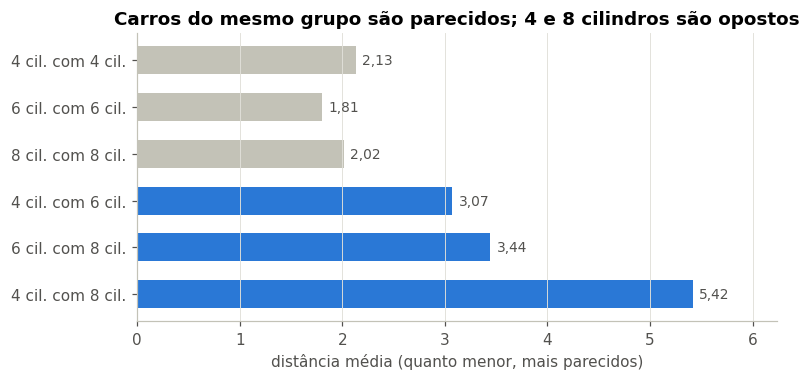

In [82]:
grupos = sorted(df["cylinders"].unique())
dist_grupos = pd.DataFrame(index=grupos, columns=grupos, dtype=float)
for g1 in grupos:
    for g2 in grupos:
        idx1 = np.where(df["cylinders"] == g1)[0]
        idx2 = np.where(df["cylinders"] == g2)[0]
        bloco = D[np.ix_(idx1, idx2)]
        if g1 == g2:
            bloco = bloco[np.triu_indices(len(idx1), k=1)]  # ignora a distância 0 de um carro com ele mesmo
        dist_grupos.loc[g1, g2] = bloco.mean()
dist_grupos.index.name = "cilindros"

# Só os 3 grupos grandes (3 e 5 cilindros têm 4 e 3 carros, pouco para comparar)
comparacoes = [("4 cil. com 4 cil.", 4, 4), ("6 cil. com 6 cil.", 6, 6), ("8 cil. com 8 cil.", 8, 8),
               ("4 cil. com 6 cil.", 4, 6), ("6 cil. com 8 cil.", 6, 8), ("4 cil. com 8 cil.", 4, 8)]
rotulos = [r for r, _, _ in comparacoes]
valores = [dist_grupos.loc[a, b] for _, a, b in comparacoes]
cores = [COR_TIPICO if a == b else COR_ATIPICO for _, a, b in comparacoes]

fig, ax = plt.subplots(figsize=(7.5, 3.4))
barras = ax.barh(rotulos[::-1], valores[::-1], color=cores[::-1], height=0.6)
for barra, v in zip(barras, valores[::-1]):
    ax.text(v + 0.06, barra.get_y() + barra.get_height() / 2, br(v, 2), va="center", fontsize=9, color=TINTA)
ax.set_xlabel("distância média (quanto menor, mais parecidos)")
ax.set_title("Carros do mesmo grupo são parecidos; 4 e 8 cilindros são opostos")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(valores) * 1.15)
fig.savefig(FIGURAS / "1_distancia_grupos_cilindros.png")
plt.show()

> Dentro do mesmo grupo (barras cinzas) a distância fica em torno de **2**. Entre um carro de **4 e um de 8 cilindros** ela é **5,4, mais que o dobro**. São dois mundos: carros leves e econômicos de um lado, pesados e potentes do outro.

### 5.4 Os carros mais longe do "carro médio"

Também medi a distância de cada carro até o **carro médio da base**. Quanto maior, mais o carro foge do comportamento geral.

In [83]:
df["dist_perfil_medio"] = np.linalg.norm(Z, axis=1)
df["atributo_mais_extremo"] = dfz.abs().idxmax(axis=1)
df["z_do_atributo_extremo"] = [dfz.loc[i, a] for i, a in zip(df.index, df["atributo_mais_extremo"])]

mais_afastados = (df.nlargest(10, "dist_perfil_medio")
                  [["id", "origem", "dist_perfil_medio", "atributo_mais_extremo", "z_do_atributo_extremo",
                    "cylinders", "km_l", "peso_kg", "horsepower", "acceleration"]])
mais_afastados.to_csv(RESULTADOS / "mais_afastados_perfil_medio.csv", index=False)

tabela_afastados = pd.DataFrame({
    "carro": mais_afastados["id"],
    "origem": mais_afastados["origem"],
    "distância do carro médio": mais_afastados["dist_perfil_medio"],
    "o que mais se destaca": [DESTAQUE[(a, 1 if z > 0 else -1)] for a, z in
                              zip(mais_afastados["atributo_mais_extremo"], mais_afastados["z_do_atributo_extremo"])],
    "cilindros": mais_afastados["cylinders"],
})
mostrar(tabela_afastados.head(10), "Os 10 carros mais longe do carro médio", indice=False,
        gradiente=["distância do carro médio"])

carro,origem,distância do carro médio,o que mais se destaca,cilindros
chevrolet impala (70),EUA,"5,49",potência muito alta,8
pontiac catalina (70),EUA,"5,45",potência muito alta,8
buick electra 225 custom (73),EUA,"5,44",potência muito alta,8
plymouth fury iii (70),EUA,"5,43",potência muito alta,8
buick estate wagon (sw) (70),EUA,"5,17",potência muito alta,8
pontiac grand prix (73),EUA,"5,08",potência muito alta,8
chrysler new yorker brougham (73),EUA,"5,08",potência muito alta,8
mercury marquis (72),EUA,"5,01",potência muito alta,8
vw pickup (82),Europa,"4,97",aceleração muito lenta,4
ford galaxie 500 (70),EUA,"4,89",potência muito alta,8


> Quase todos são **sedãs grandes americanos de 8 cilindros de 1970 a 1973**, com potência muito alta. A exceção é a **vw pickup (82)**, que se afasta pelo lado oposto: é muito lenta.
>
> **Mas tem um problema:** esses V8 eram **comuns na época**. Estar longe do centro não quer dizer que o carro é "estranho". Por isso usei métodos próprios de detecção de outliers na seção 6.

## 6. Carros fora do padrão (outliers)

Usei **três métodos** e comparei os resultados. Além dos 7 atributos, incluí a **potência por tonelada**, que mede diretamente "potência fora do esperado para o peso".

| Método | Ideia | Olha para |
|---|---|---|
| **IQR** | valor muito longe da faixa onde está a maioria dos carros | um atributo por vez |
| **Z-score** | valor a mais de 3 desvios da média | um atributo por vez |
| **Isolation Forest** | carro fácil de "isolar" dos outros | todos os atributos juntos |

### 6.1 IQR e Z-score (um atributo por vez)

In [84]:
ATRIBUTOS_OUTLIER = ATRIBUTOS + ["hp_por_tonelada"]

def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

flag_iqr = pd.DataFrame(index=df.index)
for c in ATRIBUTOS_OUTLIER:
    lo, hi = limites_iqr(df[c])
    flag_iqr[c] = (df[c] < lo) | (df[c] > hi)

z_out = (df[ATRIBUTOS_OUTLIER] - df[ATRIBUTOS_OUTLIER].mean()) / df[ATRIBUTOS_OUTLIER].std()
flag_z = z_out.abs() > 3

tabela_uni = pd.DataFrame({"IQR": flag_iqr.sum(), "Z-score": flag_z.sum()}).rename(index=NOMES)
tabela_uni.loc["carros com algum atributo fora"] = [flag_iqr.any(axis=1).sum(), flag_z.any(axis=1).sum()]
mostrar(tabela_uni, "Quantos carros ficam fora do padrão em cada atributo",
        gradiente=pd.IndexSlice[tabela_uni.index[:-1], ["IQR", "Z-score"]])

,IQR,Z-score
consumo,1,0
cilindros,0,0
cilindrada,0,0
potência,11,5
peso,0,0
aceleração,7,2
ano,0,0
potência por tonelada,8,2
carros com algum atributo fora,20,7


> Os outliers aparecem só em **potência, aceleração, potência por tonelada e consumo**. O **Z-score é mais rígido** e aponta bem menos carros (7) que o IQR (20).

### 6.2 Isolation Forest (todos os atributos juntos)

Esse método consegue pegar **combinações estranhas** que nenhum atributo sozinho mostraria, como um peso normal com uma potência alta demais. Pedi para ele apontar os **5% mais anômalos** (cerca de 20 carros) e testei se o resultado muda com outros valores:

In [85]:
Z_out = StandardScaler().fit_transform(df[ATRIBUTOS_OUTLIER])
iso = IsolationForest(n_estimators=300, contamination=0.05, random_state=SEED)
iso.fit(Z_out)
df["iso_score"] = -iso.score_samples(Z_out)        # maior = mais anômalo
flag_iso = pd.Series(iso.predict(Z_out) == -1, index=df.index)

sensibilidade = []
for cont in [0.03, 0.05, 0.08]:
    f = IsolationForest(n_estimators=300, contamination=cont, random_state=SEED).fit(Z_out).predict(Z_out) == -1
    sensibilidade.append({"pedindo os mais anômalos": f"{cont:.0%}", "carros apontados": f.sum(),
                          "dos 20 de 5%, quantos aparecem": (f & flag_iso.values).sum()})
mostrar(pd.DataFrame(sensibilidade), "O resultado muda se eu pedir mais ou menos carros?", indice=False)

pedindo os mais anômalos,carros apontados,"dos 20 de 5%, quantos aparecem"
3%,12,12
5%,20,20
8%,32,20


> **O resultado é estável:** pedindo 3% aparecem 12 carros, todos entre os 20 de 5%. Pedindo 8% aparecem 32, e os 20 continuam lá. Mudar o valor só aumenta ou diminui a lista, sem trocar os casos principais.

### 6.3 Comparando os três métodos

**Meu critério:** um carro só é **atípico** quando **pelo menos 2 dos 3 métodos** apontam ele. Assim nenhum caso depende de um método só.

In [86]:
df["out_iqr"] = flag_iqr.any(axis=1)
df["out_zscore"] = flag_z.any(axis=1)
df["out_iforest"] = flag_iso
df["n_metodos"] = df[["out_iqr", "out_zscore", "out_iforest"]].sum(axis=1)
df["atipico"] = df["n_metodos"] >= 2

def motivo(i):
    atr = sorted(set(flag_iqr.columns[flag_iqr.loc[i]]) | set(flag_z.columns[flag_z.loc[i]]))
    return ", ".join(atr) if atr else "combinação de atributos (só multivariado)"
df["motivo"] = [motivo(i) for i in df.index]

def motivo_simples(i):
    atr = sorted(set(flag_iqr.columns[flag_iqr.loc[i]]) | set(flag_z.columns[flag_z.loc[i]]))
    return ", ".join(DESTAQUE[(a, 1 if z_out.loc[i, a] > 0 else -1)] for a in atr) or "combinação incomum"
df["motivo_simples"] = [motivo_simples(i) for i in df.index]

comparacao = pd.DataFrame([
    {"método": nome, "carros apontados": df[col].sum(),
     "também apontados por outro": (df[col] & (df["n_metodos"] >= 2)).sum(),
     "só este apontou": (df[col] & (df["n_metodos"] == 1)).sum()}
    for nome, col in [("IQR", "out_iqr"), ("Z-score", "out_zscore"), ("Isolation Forest", "out_iforest")]
])
mostrar(comparacao, "Comparação dos três métodos", indice=False)

n = df["n_metodos"].value_counts()
display(Markdown(f"**Resultado:** {n.get(3, 0)} carros apontados pelos três métodos + {n.get(2, 0)} por dois = "
                 f"**{int(df['atipico'].sum())} carros atípicos**. Outros {n.get(1, 0)} foram apontados por só um método e não entraram."))

método,carros apontados,também apontados por outro,só este apontou
IQR,20,16,4
Z-score,7,7,0
Isolation Forest,20,15,5


**Resultado:** 6 carros apontados pelos três métodos + 10 por dois = **16 carros atípicos**. Outros 9 foram apontados por só um método e não entraram.

### 6.4 Os 16 carros atípicos

Separando os atípicos, aparecem **dois perfis opostos**:

In [87]:
atipicos = (df[df["atipico"]]
            .sort_values(["n_metodos", "iso_score"], ascending=False)
            [["id", "origem", "n_metodos", "out_iqr", "out_zscore", "out_iforest", "motivo",
              "cylinders", "km_l", "peso_kg", "horsepower", "hp_por_tonelada", "acceleration"]])
atipicos.to_csv(RESULTADOS / "carros_atipicos.csv", index=False)

df["tipo_atipico"] = np.where(~df["atipico"], "típico",
                      np.where(df["horsepower"] > df["horsepower"].median(), "atípico: potente", "atípico: fraco/lento"))

def tabela_perfil(tipo):
    t = df.loc[atipicos.index][df.loc[atipicos.index, "tipo_atipico"] == tipo]
    return pd.DataFrame({
        "carro": t["id"], "origem": t["origem"], "métodos": t["n_metodos"].astype(str) + " de 3",
        "o que está fora do padrão": t["motivo_simples"],
        "potência (hp)": t["horsepower"], "peso (kg)": t["peso_kg"], "consumo (km/l)": t["km_l"],
        "0–60 mph (s)": t["acceleration"],
    })

FORMATO_PERFIL = {"potência (hp)": "{:.0f}", "peso (kg)": "{:,.0f}", "consumo (km/l)": "{:.1f}", "0–60 mph (s)": "{:.1f}"}
potentes, fracos = tabela_perfil("atípico: potente"), tabela_perfil("atípico: fraco/lento")
mostrar(potentes, f"Perfil 1 — Muito potentes ({len(potentes)} carros)", indice=False, formato=FORMATO_PERFIL)
mostrar(fracos, f"Perfil 2 — Muito fracos e lentos ({len(fracos)} carros)", indice=False, formato=FORMATO_PERFIL)

so_um = df[df["n_metodos"] == 1]
tabela_so_um = pd.DataFrame({"carro": so_um["id"],
                             "método que apontou": np.select([so_um["out_iqr"], so_um["out_zscore"]], ["IQR", "Z-score"], "Isolation Forest"),
                             "o que está fora do padrão": so_um["motivo_simples"]})
mostrar(tabela_so_um, None, indice=False, recolher=f"Ver os {len(so_um)} carros apontados por só um método (não entraram)")

carro,origem,métodos,o que está fora do padrão,potência (hp),peso (kg),consumo (km/l),0–60 mph (s)
buick estate wagon (sw) (70),EUA,3 de 3,"potência muito alta, muita potência para o peso",225,1.400,"6,0","10,0"
pontiac grand prix (73),EUA,3 de 3,"potência muito alta, muita potência para o peso",230,1.940,"6,8","9,5"
buick electra 225 custom (73),EUA,3 de 3,potência muito alta,225,2.246,"5,1","11,0"
chevrolet impala (70),EUA,3 de 3,"potência muito alta, muita potência para o peso",220,1.975,"6,0","9,0"
pontiac catalina (70),EUA,3 de 3,"potência muito alta, muita potência para o peso",225,2.007,"6,0","10,0"
plymouth fury iii (70),EUA,2 de 3,"aceleração muito rápida, potência muito alta, muita potência para o peso",215,1.956,"6,0","8,5"
ford f250 (70),EUA,2 de 3,potência muito alta,215,2.093,"4,3","14,0"
chevy c20 (70),EUA,2 de 3,potência muito alta,200,1.985,"4,3","15,0"
amc ambassador dpl (70),EUA,2 de 3,"aceleração muito rápida, muita potência para o peso",190,1.746,"6,4","8,5"
mercury marquis (72),EUA,2 de 3,potência muito alta,208,2.101,"4,7","11,0"


carro,origem,métodos,o que está fora do padrão,potência (hp),peso (kg),consumo (km/l),0–60 mph (s)
vw pickup (82),Europa,3 de 3,aceleração muito lenta,52,966,"18,7","24,6"
vw dasher (diesel) (80),Europa,2 de 3,aceleração muito lenta,48,1.059,"18,5","23,7"
peugeot 504 (79),Europa,2 de 3,aceleração muito lenta,71,1.447,"11,6","24,8"


carro,método que apontou,o que está fora do padrão
plymouth 'cuda 340 (70),IQR,aceleração muito rápida
hi 1200d (70),Isolation Forest,combinação incomum
volkswagen type 3 (72),IQR,aceleração muito lenta
oldsmobile omega (73),IQR,muita potência para o peso
oldsmobile cutlass salon brougham (79),Isolation Forest,combinação incomum
mazda glc (80),IQR,muito econômico
datsun 280-zx (80),Isolation Forest,combinação incomum
oldsmobile cutlass ls (81),Isolation Forest,combinação incomum
oldsmobile cutlass ciera (diesel) (82),Isolation Forest,combinação incomum


> 1. **Muito potentes (13):** quase todos americanos de 8 cilindros de 1970 a 1973, com 190 a 230 hp (sedãs grandes, uma perua e picapes). O intruso é o **bmw 2002**, um europeu leve de 4 cilindros com potência alta para o peso dele.
> 2. **Muito fracos e lentos (3):** *vw pickup*, *vw dasher diesel* e *peugeot 504*, com 48 a 71 hp e os 0–60 mph mais lentos da base (23,7 a 24,8 s).

### 6.5 O caso da Buick: carro diferente ou erro no dado?

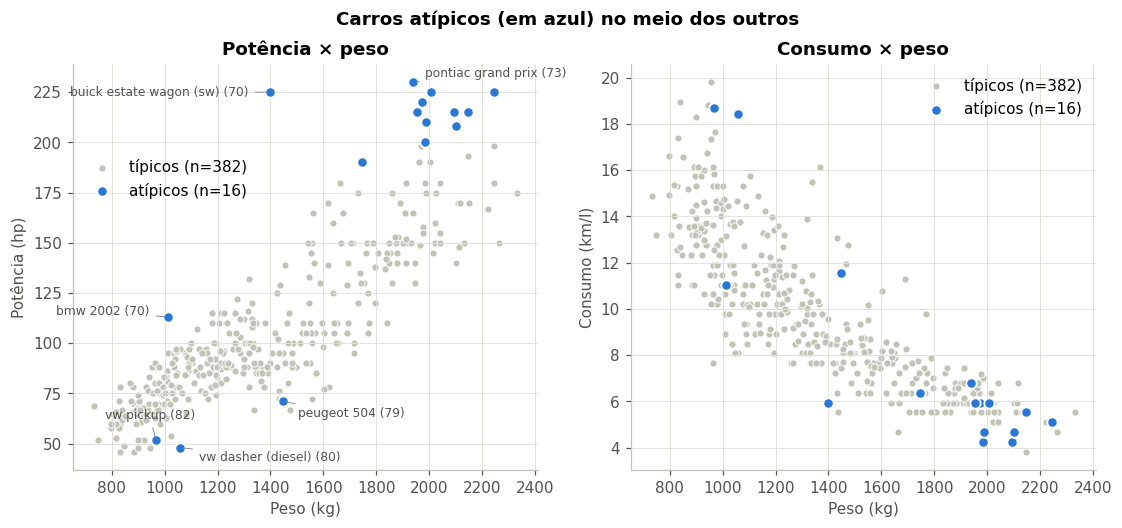

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
tip, atp = df[~df["atipico"]], df[df["atipico"]]

for ax, (col, rot) in zip(axes, [("horsepower", "Potência (hp)"), ("km_l", "Consumo (km/l)")]):
    ax.scatter(tip["peso_kg"], tip[col], s=22, c=COR_TIPICO, edgecolors="white", linewidths=0.6,
               label=f"típicos (n={len(tip)})")
    ax.scatter(atp["peso_kg"], atp[col], s=46, c=COR_ATIPICO, edgecolors="white", linewidths=1.2,
               label=f"atípicos (n={len(atp)})", zorder=3)
    ax.set_xlabel("Peso (kg)")
    ax.set_ylabel(rot)
    ax.legend(frameon=False, loc="upper left" if col == "horsepower" else "upper right",
              bbox_to_anchor=(0, 0.8) if col == "horsepower" else None)

destaques = {"buick estate wagon (sw) (70)": (-14, 0, "right"), "pontiac grand prix (73)": (8, 6, "left"),
             "bmw 2002 (70)": (-12, 4, "right"), "vw pickup (82)": (-4, 16, "center"),
             "vw dasher (diesel) (80)": (12, -6, "left"), "peugeot 504 (79)": (10, -8, "left")}
for nome, (dx, dy, ha) in destaques.items():
    r = df[df["id"] == nome].iloc[0]
    axes[0].annotate(nome, (r["peso_kg"], r["horsepower"]), xytext=(dx, dy), textcoords="offset points",
                     ha=ha, va="center", fontsize=8, color=TINTA,
                     arrowprops=dict(arrowstyle="-", color="#898781", lw=0.6))
axes[0].set_title("Potência × peso")
axes[1].set_title("Consumo × peso")
fig.suptitle("Carros atípicos (em azul) no meio dos outros", fontweight="bold")
fig.savefig(FIGURAS / "2_atipicos_potencia_consumo_peso.png")
plt.show()

No gráfico da esquerda, os potentes ficam no alto e os fracos embaixo. Mas a **buick estate wagon (sw) (70)** chama atenção: **225 hp com só ~1.400 kg**, muito mais leve que qualquer carro com potência parecida. Comparei com as outras peruas da época:

In [89]:
peruas = df[df["car_name"].str.contains(r"\(sw\)", regex=True) & (df["cylinders"] == 8) & (df["model_year"] <= 72)]
tabela_peruas = pd.DataFrame({"perua (8 cilindros)": peruas["id"], "potência (hp)": peruas["horsepower"],
                              "peso (kg)": peruas["peso_kg"]})
mostrar(tabela_peruas, "Peruas de 8 cilindros de 1970 a 1972", indice=False,
        formato={"potência (hp)": "{:.0f}", "peso (kg)": "{:,.0f}"},
        destaque=("perua (8 cilindros)", "buick estate wagon (sw) (70)"))

perua (8 cilindros),potência (hp),peso (kg)
buick estate wagon (sw) (70),225,1.400
dodge monaco (sw) (71),180,2.248
ford country squire (sw) (71),170,2.153
pontiac safari (sw) (71),175,2.331
amc matador (sw) (72),150,1.765
chevrolet chevelle concours (sw) (72),130,1.859
ford gran torino (sw) (72),140,1.948
plymouth satellite custom (sw) (72),150,1.849


> Todas as outras pesam entre **1.765 e 2.331 kg**. Só a Buick aparece com 1.400. O mais provável é que **o peso dela esteja errado na base**.
>
> **Lição: um outlier nem sempre é um carro diferente, pode ser um erro no dado.** Mantive a Buick (não tenho fonte oficial para corrigir), mas avisei sobre isso no resumo enviado à LLM e na conclusão.

## 7. Análise com Pandas

### 7.1 Por origem

In [90]:
por_origem = df.groupby("origem").agg(
    carros=("id", "count"),
    km_l_medio=("km_l", "mean"),
    peso_kg_medio=("peso_kg", "mean"),
    hp_medio=("horsepower", "mean"),
    aceleracao_media=("acceleration", "mean"),
    pct_8_cilindros=("cylinders", lambda s: (s == 8).mean() * 100),
    atipicos=("atipico", "sum"),
)
por_origem["pct_atipicos"] = por_origem["atipicos"] / por_origem["carros"] * 100
por_origem.to_csv(RESULTADOS / "resumo_por_origem.csv")

tabela_origem = por_origem[["carros", "km_l_medio", "peso_kg_medio", "hp_medio", "pct_8_cilindros", "atipicos"]].copy()
tabela_origem.index.name = None
tabela_origem.columns = ["carros", "consumo médio (km/l)", "peso médio (kg)", "potência média (hp)", "com 8 cilindros", "atípicos"]
mostrar(tabela_origem, "O carro médio de cada origem", gradiente=["consumo médio (km/l)"],
        formato={"consumo médio (km/l)": "{:.1f}", "peso médio (kg)": "{:,.0f}", "potência média (hp)": "{:.0f}",
                 "com 8 cilindros": "{:.0f}%"})

,carros,consumo médio (km/l),peso médio (kg),potência média (hp),com 8 cilindros,atípicos
EUA,249,"8,5",1.525,118,41%,12
Europa,70,"11,9",1.099,80,0%,4
Japão,79,"12,9",1.008,80,0%,0


> Os americanos são **mais pesados, mais potentes e gastam mais** (8,5 km/l contra 11,9 da Europa e 12,9 do Japão). **41% deles têm 8 cilindros**; europeus e japoneses não têm nenhum. Os japoneses não têm nenhum atípico.

### 7.2 Ao longo dos anos

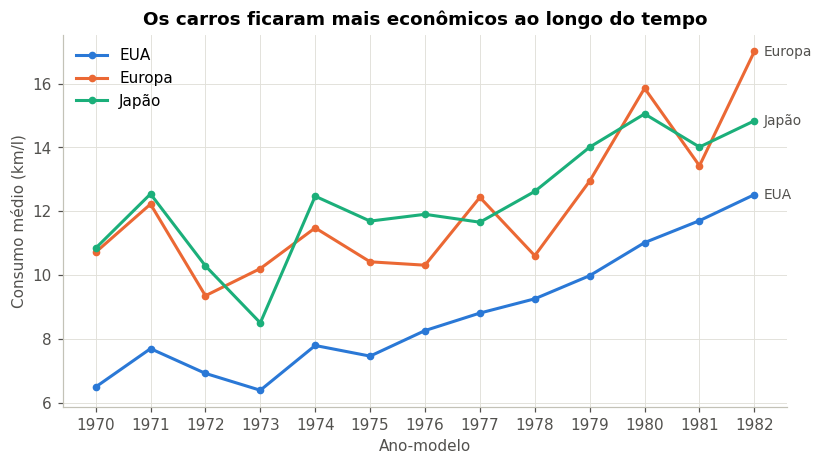

In [91]:
por_ano = df.pivot_table(index="ano", columns="origem", values="km_l", aggfunc="mean")
por_ano.to_csv(RESULTADOS / "km_l_por_ano_origem.csv")

fig, ax = plt.subplots(figsize=(8.5, 4.4))
for org in ["EUA", "Europa", "Japão"]:
    ax.plot(por_ano.index, por_ano[org], color=COR_ORIGEM[org], lw=2, marker="o", ms=4, label=org)
    ax.annotate(org, (por_ano.index[-1], por_ano[org].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=TINTA)
ax.set_xlabel("Ano-modelo")
ax.set_ylabel("Consumo médio (km/l)")
ax.set_title("Os carros ficaram mais econômicos ao longo do tempo")
ax.set_xticks(por_ano.index)
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURAS / "3_km_l_por_ano_origem.png")
plt.show()

> Os americanos saem de **6,5 km/l em 1970 para 12,5 km/l em 1982**, e a tendência de melhora aparece nas três origens, com algumas quedas no caminho. Isso ajuda a entender por que os atípicos potentes são todos de 1970–73: os carrões de 8 cilindros foram sumindo.
>
> **Isso é uma associação no tempo, não prova de causa.** O período coincide com as crises do petróleo de 1973 e 1979, mas a base não tem dados para confirmar o motivo.

### 7.3 Típicos × atípicos

In [92]:
COMPARAR = ["km_l", "peso_kg", "horsepower", "hp_por_tonelada", "acceleration", "cylinders", "cilindrada_l", "model_year"]
tipico_atipico = df.groupby(df["atipico"].map({False: "típico", True: "atípico"}))[COMPARAR].mean().T
tipico_atipico["dif_%"] = (tipico_atipico["atípico"] / tipico_atipico["típico"] - 1) * 100
tipico_atipico = tipico_atipico[["típico", "atípico", "dif_%"]]
tipico_atipico.to_csv(RESULTADOS / "tipico_vs_atipico.csv")

por_tipo = df.groupby("tipo_atipico")[["km_l", "peso_kg", "horsepower", "hp_por_tonelada", "acceleration", "model_year"]].mean()
por_tipo["carros"] = df["tipo_atipico"].value_counts()
por_tipo.to_csv(RESULTADOS / "tipico_vs_tipos_de_atipico.csv")

g = por_tipo.loc[["típico", "atípico: potente", "atípico: fraco/lento"]]
lado_a_lado = pd.DataFrame({
    "carros":                   [f"{v:.0f}" for v in g["carros"]],
    "consumo (km/l)":           [br(v) for v in g["km_l"]],
    "peso (kg)":                [br(v, 0) for v in g["peso_kg"]],
    "potência (hp)":            [br(v, 0) for v in g["horsepower"]],
    "potência por tonelada":    [br(v, 0) for v in g["hp_por_tonelada"]],
    "0–60 mph (s)":             [br(v) for v in g["acceleration"]],
    "ano médio":                [f"{1900 + v:.0f}" for v in g["model_year"]],
}, index=["Típicos", "Atípicos potentes", "Atípicos fracos/lentos"]).T
mostrar(lado_a_lado, "Média de cada grupo, lado a lado")

,Típicos,Atípicos potentes,Atípicos fracos/lentos
carros,382,13,3
consumo (km/l),"10,1","5,9","16,2"
peso (kg),1.330,1.892,1.157
potência (hp),101,207,57
potência por tonelada,76,111,49
0–60 mph (s),"15,7",11,"24,4"
ano médio,1976,1971,1980


> - **Potentes:** o **dobro da potência** dos típicos (207 × 101 hp) e consumo bem pior (**5,9 × 10,1 km/l**). São do começo do período (1971).
> - **Fracos/lentos:** bem menos potência por tonelada (49 × 76) e muito mais lentos (**24,4 × 15,7 s**). São do fim do período (1980).
>
> Separei os dois perfis porque, juntos, a média enganaria: um efeito cancelaria o outro.

## 8. Resumo para a LLM

Aqui montei, no Python, **o único conteúdo enviado para a LLM**: um JSON com os resultados (contagens, médias e nomes dos carros). **A base de dados não é enviada.**

In [93]:
def r2(v):
    return round(float(v), 2)

def ficha(row):
    return {"modelo": row["id"], "origem": row["origem"], "cilindros": int(row["cylinders"]),
            "km_l": r2(row["km_l"]), "peso_kg": int(round(row["peso_kg"])), "potencia_hp": int(round(row["horsepower"])),
            "hp_por_tonelada": r2(row["hp_por_tonelada"]), "aceleracao_0_60mph_s": r2(row["acceleration"])}

por_id = df.set_index("id")
resumo = {
    "dataset": "Auto MPG (UCI) - modelos de carro dos anos-modelo 1970 a 1982; cada registro é um modelo em um ano",
    "registros_analisados": int(len(df)),
    "preparacao": {
        "ausentes": "6 valores de potência ausentes, preenchidos com a mediana dos carros com o mesmo nº de cilindros",
        "duplicadas": 0,
        "marcas_corrigidas": f"{int(corrigidas.sum())} nomes de marca padronizados (ex.: vw/vokswagen -> volkswagen, chevy/chevroelt -> chevrolet)",
        "atributos_na_distancia": ATRIBUTOS,
        "padronizacao": "Z-score (sem ela o peso responderia por mais de 98% da distância)",
    },
    "carros_por_cilindros": {str(k): int(v) for k, v in df["cylinders"].value_counts().sort_index().items()},
    "similaridade": {
        "metrica": "distância Euclidiana nos 7 atributos padronizados",
        "distancia_media_entre_dois_carros": r2(dist_pares.mean()),
        "pares_mais_semelhantes": [
            {"carro_a": ficha(por_id.loc[a].to_dict() | {"id": a}), "carro_b": ficha(por_id.loc[b].to_dict() | {"id": b}),
             "distancia": r2(d)}
            for a, b, d in pares_semelhantes[["carro A", "carro B", "distância"]].head(5).values
        ],
        "pct_vizinho_mais_proximo_com": {k: round(v, 1) for k, v in vizinho_mesmo.items()},
        "distancia_media_entre_grupos_de_cilindros": {
            "4x4": r2(dist_grupos.loc[4, 4]), "6x6": r2(dist_grupos.loc[6, 6]), "8x8": r2(dist_grupos.loc[8, 8]),
            "4x6": r2(dist_grupos.loc[4, 6]), "4x8": r2(dist_grupos.loc[4, 8]), "6x8": r2(dist_grupos.loc[6, 8]),
        },
    },
    "afastamento_do_perfil_medio": {
        "distancia_media_ao_perfil_medio": r2(df["dist_perfil_medio"].mean()),
        "mais_afastados": [
            ficha(r) | {"distancia_ao_perfil_medio": r2(r["dist_perfil_medio"]),
                        "atributo_mais_extremo": r["atributo_mais_extremo"], "z_desse_atributo": r2(r["z_do_atributo_extremo"])}
            for _, r in df.nlargest(5, "dist_perfil_medio").iterrows()
        ],
    },
    "outliers": {
        "atributos_avaliados": ATRIBUTOS_OUTLIER,
        "iqr_por_atributo": {k: int(v) for k, v in flag_iqr.sum().items() if v > 0},
        "zscore_maior_que_3_por_atributo": {k: int(v) for k, v in flag_z.sum().items() if v > 0},
        "carros_por_metodo": {"IQR": int(df["out_iqr"].sum()), "Z-score": int(df["out_zscore"].sum()),
                              "Isolation Forest (contamination=0.05)": int(df["out_iforest"].sum())},
        "carros_por_numero_de_metodos_que_apontam": {str(k): int(v) for k, v in df["n_metodos"].value_counts().sort_index().items()},
        "criterio_atipico": "apontado por pelo menos 2 dos 3 métodos",
        "total_atipicos": int(df["atipico"].sum()),
        "atipicos": [ficha(r) | {"metodos": int(r["n_metodos"]), "atributos_fora_do_padrao": r["motivo"]}
                     for _, r in df[df["atipico"]].sort_values("iso_score", ascending=False).iterrows()],
        "observacao_qualidade": ("buick estate wagon (sw) (70) tem 225 hp e peso registrado de 3086 lb (~1400 kg); outras peruas de 8 cilindros "
                                 "de 1971-72 na base pesam 3892 a 5140 lb, então o peso provavelmente foi registrado errado"),
    },
    "medias_tipico_vs_atipico": {
        grupo: {c: r2(v) for c, v in por_tipo.loc[grupo, ["km_l", "peso_kg", "horsepower", "hp_por_tonelada", "acceleration"]].items()}
               | {"carros": int(por_tipo.loc[grupo, "carros"])}
        for grupo in por_tipo.index
    },
    "por_origem": {org: {"carros": int(r["carros"]), "km_l_medio": r2(r["km_l_medio"]), "peso_kg_medio": int(round(r["peso_kg_medio"])),
                         "hp_medio": r2(r["hp_medio"]), "pct_8_cilindros": r2(r["pct_8_cilindros"]), "atipicos": int(r["atipicos"])}
                   for org, r in por_origem.iterrows()},
    "km_l_medio_por_ano": {str(a): r2(v) for a, v in df.groupby("ano")["km_l"].mean().items()},
}

resumo_json = json.dumps(resumo, ensure_ascii=False, indent=2)
ARQ_RESUMO = RESULTADOS / "resumo_para_llm.json"
_ = ARQ_RESUMO.write_text(resumo_json, encoding="utf-8")

In [94]:
display(Markdown(
    f"O resumo tem **{len(resumo_json):,} caracteres**".replace(",", ".") + " e leva: os 5 pares mais parecidos, os 5 carros mais longe do "
    f"carro médio, os {len(resumo['outliers']['atipicos'])} atípicos, as contagens de cada método, as médias por grupo, por origem e por ano, "
    "e o aviso sobre o peso da Buick."))
display(HTML(f"<details><summary><b>Ver o JSON completo enviado</b> (clique para abrir)</summary>"
             f"<pre style='font-size: 0.85em; max-height: 420px; overflow: auto;'>{escape(resumo_json)}</pre></details>"))

# Conferência de reprodutibilidade: a execução atual chegou nos mesmos números citados nos textos?
conferencia = {
    "carros analisados": (len(df), 398),
    "potências preenchidas": (int(df["hp_imputado"].sum()), 6),
    "marcas após correção": (df["marca"].nunique(), 29),
    "par mais parecido": (f"{pares_semelhantes.iloc[0]['carro A']} × {pares_semelhantes.iloc[0]['carro B']}",
                          "chevrolet chevette (78) × honda accord lx (78)"),
    "vizinho com mesmo nº de cilindros (%)": (round(vizinho_mesmo["mesmo nº de cilindros"], 1), 98.5),
    "outliers IQR / Z-score / I. Forest": (f"{df['out_iqr'].sum()} / {df['out_zscore'].sum()} / {df['out_iforest'].sum()}", "20 / 7 / 20"),
    "carros atípicos": (int(df["atipico"].sum()), 16),
    "atípicos potentes / fracos": (f"{(df['tipo_atipico'] == 'atípico: potente').sum()} / {(df['tipo_atipico'] == 'atípico: fraco/lento').sum()}", "13 / 3"),
}
diferentes = {k: v for k, v in conferencia.items() if str(v[0]) != str(v[1])}
if diferentes:
    display(Markdown("> ⚠️ **Algum resultado mudou nesta execução** (provavelmente outra versão das bibliotecas). "
                     "Os textos foram escritos com estes valores: " + "; ".join(f"{k}: {v[1]} (agora {v[0]})" for k, v in diferentes.items())))
else:
    display(Markdown("> ✔ *Conferência automática: esta execução chegou exatamente nos mesmos números citados nos textos.*"))

O resumo tem **14.222 caracteres** e leva: os 5 pares mais parecidos, os 5 carros mais longe do carro médio, os 16 atípicos, as contagens de cada método, as médias por grupo, por origem e por ano, e o aviso sobre o peso da Buick.

> ✔ *Conferência automática: esta execução chegou exatamente nos mesmos números citados nos textos.*

## 9. A LLM (Google Gemini)

Só agora, com a mineração pronta, entra a LLM: o **Google Gemini**, chamado pela biblioteca oficial `google-genai`.

> **Mudança em relação à proposta:** eu tinha previsto o `gemini-2.5-flash`, mas a API respondeu que esse modelo não está mais disponível para contas novas e indicou o **`gemini-3.8-flash`**, que foi o que usei.

A chave da API fica numa variável de ambiente e **não aparece no código**.

### 9.1 O prompt

O prompt tem três partes: **contexto** (o que são os dados), **limites** (não inventar, não afirmar causa) e **formato** (seções fixas na resposta).

In [95]:
PROMPT_SISTEMA = '''Você é um analista de dados que ajuda a interpretar resultados de um projeto de Mineração de Dados.
Regras obrigatórias:
- Use SOMENTE as informações do resumo JSON fornecido. Não invente valores, carros, médias ou porcentagens.
- Ao citar um número, use exatamente o valor que aparece no resumo.
- Se algo não puder ser respondido com o resumo, diga explicitamente que a informação não está disponível.
- Não afirme relação de causa. Quando sugerir uma explicação, marque-a como "hipótese".
- Responda em português do Brasil, em linguagem clara para quem não é especialista.'''

PROMPT_USUARIO = f'''CONTEXTO
Os dados são especificações técnicas de modelos de carro dos anos-modelo 1970 a 1982 (base pública Auto MPG, da UCI).
Não há nenhum dado de pessoas. Toda a análise já foi feita em Python: limpeza, padronização Z-score,
distância Euclidiana entre carros e detecção de outliers por IQR, Z-score e Isolation Forest.
Unidades: consumo em km/l (maior = mais econômico), peso em kg, potência em hp,
aceleração em segundos de 0 a 60 mph (maior = mais lento).
Pergunta da análise: quais carros têm perfis técnicos mais semelhantes, quais se afastam do comportamento geral
e o que caracteriza esses casos atípicos (consumo, potência ou aceleração fora do esperado para o peso)?

RESUMO DOS RESULTADOS (JSON)
{resumo_json}

TAREFA
Interprete os resultados acima e responda em Markdown, exatamente com estas seções:
## 1. Principais padrões
(3 a 5 tópicos curtos)
## 2. Carros mais semelhantes
(explique o que os pares mais próximos têm em comum e o que isso indica)
## 3. Casos atípicos
(agrupe os atípicos por tipo e explique o que os diferencia dos carros típicos; comente a observação de qualidade dos dados)
## 4. Concordância entre os métodos de outliers
## 5. Resumo executivo
(no máximo 5 linhas)
## 6. Perguntas adicionais
(3 perguntas que poderiam ser investigadas depois)
'''

PROMPT_COMPLETO = "=== INSTRUÇÃO DE SISTEMA ===\n" + PROMPT_SISTEMA + "\n\n=== MENSAGEM ===\n" + PROMPT_USUARIO
ARQ_PROMPT = RESULTADOS / "prompt_llm.txt"

inicio = PROMPT_USUARIO[:PROMPT_USUARIO.index("RESUMO DOS RESULTADOS")]
tarefa = PROMPT_USUARIO[PROMPT_USUARIO.index("TAREFA"):]
display(Markdown("**Limites (instrução de sistema):**\n```text\n" + PROMPT_SISTEMA + "\n```\n"
                 "**Mensagem (contexto + resumo + formato):**\n```text\n" + inicio
                 + "RESUMO DOS RESULTADOS (JSON)\n[... o JSON da seção 8 ...]\n\n" + tarefa + "\n```"))

**Limites (instrução de sistema):**
```text
Você é um analista de dados que ajuda a interpretar resultados de um projeto de Mineração de Dados.
Regras obrigatórias:
- Use SOMENTE as informações do resumo JSON fornecido. Não invente valores, carros, médias ou porcentagens.
- Ao citar um número, use exatamente o valor que aparece no resumo.
- Se algo não puder ser respondido com o resumo, diga explicitamente que a informação não está disponível.
- Não afirme relação de causa. Quando sugerir uma explicação, marque-a como "hipótese".
- Responda em português do Brasil, em linguagem clara para quem não é especialista.
```
**Mensagem (contexto + resumo + formato):**
```text
CONTEXTO
Os dados são especificações técnicas de modelos de carro dos anos-modelo 1970 a 1982 (base pública Auto MPG, da UCI).
Não há nenhum dado de pessoas. Toda a análise já foi feita em Python: limpeza, padronização Z-score,
distância Euclidiana entre carros e detecção de outliers por IQR, Z-score e Isolation Forest.
Unidades: consumo em km/l (maior = mais econômico), peso em kg, potência em hp,
aceleração em segundos de 0 a 60 mph (maior = mais lento).
Pergunta da análise: quais carros têm perfis técnicos mais semelhantes, quais se afastam do comportamento geral
e o que caracteriza esses casos atípicos (consumo, potência ou aceleração fora do esperado para o peso)?

RESUMO DOS RESULTADOS (JSON)
[... o JSON da seção 8 ...]

TAREFA
Interprete os resultados acima e responda em Markdown, exatamente com estas seções:
## 1. Principais padrões
(3 a 5 tópicos curtos)
## 2. Carros mais semelhantes
(explique o que os pares mais próximos têm em comum e o que isso indica)
## 3. Casos atípicos
(agrupe os atípicos por tipo e explique o que os diferencia dos carros típicos; comente a observação de qualidade dos dados)
## 4. Concordância entre os métodos de outliers
## 5. Resumo executivo
(no máximo 5 linhas)
## 6. Perguntas adicionais
(3 perguntas que poderiam ser investigadas depois)

```

### 9.2 A chamada à API

A resposta fica **salva** em `resultados/resposta_llm.md`. Ao rodar de novo, o notebook usa a resposta salva (a que eu avaliei na seção 10) em vez de chamar a API e receber um texto diferente.

In [96]:
MODELO = "gemini-3.8-flash"
TEMPERATURA = 0.2          # baixa: respostas mais fiéis ao resumo e menos "criativas"
REEXECUTAR_LLM = False     # True = chama a API de novo mesmo que já exista resposta salva
ARQ_RESPOSTA = RESULTADOS / "resposta_llm.md"
ARQ_META = RESULTADOS / "resposta_llm_metadados.json"


def chamar_gemini(instrucao_sistema: str, mensagem: str, tentativas: int = 6) -> str:
    import time
    try:
        import google.genai  # noqa: F401
    except ImportError:      # instala a biblioteca só se for realmente chamar a API
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "google-genai"])
    from google import genai
    from google.genai import types, errors

    cliente = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    for n in range(1, tentativas + 1):
        try:
            resposta = cliente.models.generate_content(
                model=MODELO,
                contents=mensagem,
                config=types.GenerateContentConfig(system_instruction=instrucao_sistema, temperature=TEMPERATURA),
            )
            return resposta.text
        except errors.ServerError as e:      # 5xx = serviço sobrecarregado: espera e tenta de novo
            if n == tentativas:
                raise
            espera = 15 * n
            print(f"  tentativa {n} falhou ({e.code}); nova tentativa em {espera}s...")
            time.sleep(espera)


resposta_llm = None
if ARQ_RESPOSTA.exists() and not REEXECUTAR_LLM:
    resposta_llm = ARQ_RESPOSTA.read_text(encoding="utf-8")
    meta = json.loads(ARQ_META.read_text(encoding="utf-8")) if ARQ_META.exists() else {}
    print(f"Usando a resposta salva (gerada em {meta.get('gerado_em', '?').replace('T', ' ')} pelo modelo {meta.get('modelo', '?')}).")
    if ARQ_PROMPT.exists() and ARQ_PROMPT.read_text(encoding="utf-8") != PROMPT_COMPLETO:
        print("ATENÇÃO: o prompt gerado agora é diferente do que foi enviado quando a resposta foi gerada.")
    else:
        print("Conferido: o prompt gerado agora é idêntico ao que foi enviado para gerar essa resposta.")
elif os.environ.get("GEMINI_API_KEY"):
    print(f"Chamando {MODELO}...")
    resposta_llm = chamar_gemini(PROMPT_SISTEMA, PROMPT_USUARIO)
    ARQ_PROMPT.write_text(PROMPT_COMPLETO, encoding="utf-8")
    ARQ_RESPOSTA.write_text(resposta_llm, encoding="utf-8")
    ARQ_META.write_text(json.dumps({"modelo": MODELO, "temperatura": TEMPERATURA,
                                    "gerado_em": datetime.now().isoformat(timespec="seconds"),
                                    "caracteres_enviados": len(PROMPT_SISTEMA) + len(PROMPT_USUARIO)},
                                   ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Resposta salva em {ARQ_RESPOSTA}.")
else:
    print("Não há resposta salva nem a variável GEMINI_API_KEY. Defina a chave e execute novamente.")

Usando a resposta salva (gerada em 2026-11-20 11:44:14 pelo modelo gemini-3.8-flash).
Conferido: o prompt gerado agora é idêntico ao que foi enviado para gerar essa resposta.


### 9.3 A resposta do Gemini

*Exatamente como veio, sem edição:*

In [97]:
if resposta_llm:
    # títulos rebaixados e tudo dentro de um bloco citado, para não confundir com as seções do notebook
    texto = re.sub(r"^#{1,3} ", "#### ", resposta_llm, flags=re.M)
    display(Markdown(chr(10).join("> " + linha for linha in texto.splitlines())))

> #### 1. Principais padrões
> 
> * **Predomínio e separação por cilindros:** A base de 398 registros concentra-se em carros de 4 cilindros (204) e 8 cilindros (103). A quantidade de cilindros dita fortemente a proximidade técnica: a chance de o vizinho mais próximo ter o mesmo número de cilindros é de 98,5%.
> * **Diferenças marcantes por origem:** Os modelos dos EUA têm maior peso médio (1525 kg), maior potência média (118,48 hp) e menor rendimento (8,54 km/l), concentrando 41,37% de motores de 8 cilindros. Em contrapartida, os veículos do Japão e da Europa são mais leves (1008 kg e 1099 kg) e mais econômicos (12,95 km/l e 11,86 km/l), sem nenhum modelo de 8 cilindros.
> * **Evolução do consumo ao longo dos anos:** O rendimento médio aumentou de forma consistente no período analisado, saindo de 7,52 km/l em 1970 para 13,48 km/l em 1982 (com pico de 14,33 km/l em 1980).
> * **Convergência entre montadoras:** Em 74,9% dos casos, o modelo mais parecido pertence à mesma região de origem, mas apenas em 17,8% pertence à mesma marca, indicando que fabricantes diferentes desenvolviam veículos com fichas técnicas quase idênticas.
> 
> ---
> 
> #### 2. Carros mais semelhantes
> 
> Os pares com menor distância Euclidiana reúnem modelos do mesmo ano (fato presente em 56,0% dos vizinhos mais próximos) e com a mesma contagem de cilindros. O par mais próximo de toda a base é formado por **chevrolet chevette (78)** (EUA) e **honda accord lx (78)** (Japão), com distância de apenas 0,08. Ambos possuem 4 cilindros, exatamente 68 hp de potência, pesos quase idênticos (977 kg vs. 968 kg), acelerações muito próximas (16,5 s vs. 16,6 s) e consumos semelhantes (12,75 km/l vs. 12,54 km/l). 
> 
> Outros exemplos incluem **volkswagen jetta (81)** e **honda prelude (81)** (distância 0,12), além de **mazda glc 4 (81)** e **ford escort 4w (81)** (distância 0,15). Isso indica que, ao projetar veículos para atender a uma mesma categoria e período, montadoras de origens distintas convergiram para especificações praticamente espelhadas (como hipótese, para disputar o mesmo perfil de consumidor no mercado).
> 
> ---
> 
> #### 3. Casos atípicos
> 
> Adotando o critério de consenso (apontados por ao menos 2 métodos), foram detectados **16 carros atípicos**, segmentados em dois grupos principais:
> 
> * **Atípicos potentes (13 carros):** Formado quase exclusivamente por modelos norte-americanos do início da década de 1970 com motores V8 (como buick electra 225 custom 1973, chevrolet impala 1970 e pontiac grand prix 1973). Em comparação com os veículos típicos, eles apresentam média de potência de 207,0 hp (contra 100,99 hp dos típicos), peso médio de 1892,21 kg (contra 1330,31 kg), aceleração média rápida de 11,04 s (contra 15,65 s) e consumo muito mais elevado, registrando 5,89 km/l (contra 10,09 km/l dos típicos). O bmw 2002 (70) também se destaca nesse grupo devido à sua elevada relação potência/peso (111,51 hp/tonelada para um veículo de 4 cilindros).
> * **Atípicos fracos/lentos (3 carros):** Formado por vw dasher diesel (80), vw pickup (82) e peugeot 504 (79). Caracterizam-se por acelerações muito lentas (média de 24,37 s de 0 a 60 mph), potência reduzida (média de 57,0 hp) e relação hp/tonelada de apenas 49,4, embora atinjam um rendimento favorável de 16,24 km/l.
> * **Observação de qualidade dos dados:** O modelo **buick estate wagon (sw) (70)** foi apontado pelos 3 métodos como atípico, exibindo uma relação atípica de 160,74 hp/tonelada devido a 225 hp e peso registrado de 1400 kg (3086 lb). O resumo aponta que outras peruas de 8 cilindros do mesmo período (1971-1972) pesam entre 3892 e 5140 lb, o que indica que esse peso provavelmente foi registrado com erro na base de dados original.
> 
> ---
> 
> #### 4. Concordância entre os métodos de outliers
> 
> A concordância entre os três métodos aplicados (IQR, Z-score e Isolation Forest) variou conforme o rigor de cada algoritmo:
> * **Z-score (> 3):** Foi o mais conservador, identificando apenas 7 carros ao todo (5 em potência, 2 em aceleração e 2 em hp/tonelada).
> * **IQR e Isolation Forest (contamination = 0,05):** Ambos identificaram 20 carros cada.
> * **Concordância geral:** A grande maioria dos dados (373 carros) não foi considerada atípica por nenhum método. Dos modelos sinalizados, 9 foram acusados por apenas 1 método, 10 por 2 métodos e 6 carros foram rotulados simultaneamente pelos 3 métodos.
> 
> ---
> 
> #### 5. Resumo executivo
> 
> A análise de 398 veículos mostrou que número de cilindros e ano de fabricação governam a semelhança técnica, gerando modelos quase idênticos entre marcas de diferentes continentes. Foram identificados 16 veículos atípicos, divididos entre modelos V8 norte-americanos do início dos anos 1970 (altíssimo peso e potência) e modelos europeus de aceleração extremamente lenta. Detectou-se também provável erro de registro no peso da perua Buick Estate Wagon (1970).
> 
> ---
> 
> #### 6. Perguntas adicionais
> 
> 1. **Qual o impacto do provável erro de peso da Buick Estate Wagon (1970)?** Caso o peso seja corrigido para a faixa das outras peruas (entre 3892 e 5140 lb), o modelo ainda seria apontado como atípico pelos métodos multivariados?
> 2. **Existe correlação entre o tipo de combustível e a lentidão dos atípicos europeus?** Como a base registra versões diesel (ex.: VW Dasher), seria útil verificar se a baixa aceleração é comum a todos os veículos a diesel da base (informação não detalhada para os demais carros no resumo).
> 3. **Quais foram as 9 variáveis/modelos apontados por apenas 1 método de outlier?** Investigar por que houve discordância entre Isolation Forest e IQR nesses 9 casos específicos ajudaria a calibrar melhor a detecção de anomalias.

## 10. Conferindo a resposta da LLM

Não aceitei a resposta direto. Fiz duas conferências: uma **automática** e uma **leitura crítica**, comparando com os resultados do código.

### 10.1 Conferência automática

Verifiquei se a LLM **inventou algum número** (todo número citado tem que existir no resumo) ou **citou algum carro que não estava no resumo**.

In [98]:
def numeros(texto):
    # pega números como 225, 5.49, 5,49, 1.400 (milhar) e 98%
    return re.findall(r"(?<![\w])\d+(?:[.,]\d+)*", texto)


def numero_confere(n, referencia):
    candidatos = {n.replace(",", "."), n.replace(".", "").replace(",", "."), n.replace(",", "")}
    for c in candidatos:
        try:
            v = float(c)
        except ValueError:
            continue
        if any(abs(v - r) <= max(0.051, abs(r) * 0.005) for r in referencia):
            return True
    return False


if resposta_llm:
    referencia = set()
    for n in numeros(PROMPT_USUARIO):
        for c in {n.replace(",", "."), n.replace(".", "").replace(",", "."), n.replace(",", "")}:
            try:
                referencia.add(float(c))
            except ValueError:
                pass
    referencia |= {1, 2, 3, 4, 5, 6}   # numeração das seções da resposta

    citados = numeros(resposta_llm)
    nao_conferem = sorted({n for n in citados if not numero_confere(n, referencia)})

    texto_baixo = resposta_llm.lower()
    nomes_no_resumo = {m.rsplit(" (", 1)[0].lower() for m in re.findall(r'"modelo": "([^"]+)"', resumo_json)}
    citados_fora = sorted({n for n in df["car_name"].str.lower().unique()
                           if n not in nomes_no_resumo and len(n) > 6 and n in texto_baixo
                           and not any(n in x for x in nomes_no_resumo)})

    mostrar(pd.DataFrame([
        {"conferência": "números citados pela LLM", "resultado": len(citados)},
        {"conferência": "números inventados (não estão no resumo)", "resultado": len(nao_conferem)},
        {"conferência": "carros citados que não estavam no resumo", "resultado": len(citados_fora)},
    ]), "Conferência automática", indice=False)
    for n in nao_conferem:
        print("Número sem correspondência:", n)
    for c in citados_fora:
        print("Carro fora do resumo:", c)
else:
    print("Sem resposta da LLM para verificar.")

conferência,resultado
números citados pela LLM,119
números inventados (não estão no resumo),0
carros citados que não estavam no resumo,0


> **Nenhum número e nenhum carro inventado.** Mas essa conferência só pega dado inventado. **Erro de interpretação** só aparece lendo com atenção:

### 10.2 Leitura crítica

| O que a LLM disse | O que os dados mostram | |
|---|---|:---:|
| Todos os números citados | Os 119 existem no resumo | ✔ |
| A Buick é provável erro de registro | Confere com a seção 6.5 | ✔ |
| Dois perfis de atípicos: potentes e fracos/lentos | Confere com a seção 6.4 | ✔ |
| "Os pares mais parecidos são do mesmo ano (56,0% dos vizinhos)" | Os 56% são sobre **todos** os carros. Entre os 10 pares mais parecidos, **todos** são do mesmo ano | ✘ número no lugar errado |
| "O consumo aumentou **de forma consistente**" | Os valores estão certos, mas o consumo **cai** em 1972, 1973, 1975 e 1981 | ✘ exagero |
| "Fabricantes diferentes faziam carros quase idênticos" | Os dados só mostram que o carro mais parecido raramente é da mesma marca, o que é normal com 29 marcas. Ela não marcou isso como hipótese | ✘ conclusão sem base |
| "Cilindros e ano **governam** a semelhança" | O ano aparece porque **eu coloquei o ano na comparação**: é consequência da escolha, não descoberta | ⚠ meia verdade |
| "Os fracos/lentos têm rendimento favorável (16,24 km/l)" | A média esconde o *peugeot 504*, com 11,56 km/l, quase igual aos típicos | ⚠ simplificação |

**Outras explicações possíveis** que a LLM não levantou:
- As **picapes** (*ford f250*, *chevy c20*, *dodge d200*, *vw pickup*) são veículos de trabalho. Elas parecem atípicas em parte porque **a base não diz o tipo de carroceria**.
- Os V8 de 1970–73 são extremos na base toda, mas **eram normais na época deles**.

## 11. Conclusão

| Pergunta | Resposta |
|---|---|
| **Quais carros são mais parecidos?** | Os que têm o **mesmo número de cilindros** (98,5% dos casos). A marca quase não importa: o par mais parecido é um **Chevette (EUA)** e um **Accord (Japão)**. |
| **Quais fogem do padrão?** | **16 carros**, apontados por pelo menos 2 de 3 métodos. |
| **O que eles têm de diferente?** | São de dois tipos: **13 muito potentes** (V8 americanos de 1970–73, que gastam muito) e **3 muito fracos e lentos** (europeus pequenos do fim do período). |

### O que eu aprendi

1. **Padronizar é essencial:** sem isso, o peso decidiria 98% da comparação.
2. **Cada método de outlier vê uma coisa diferente.** Exigir 2 de 3 deu um resultado mais confiável.
3. **Outlier precisa ser investigado:** o carro mais "estranho", a Buick, provavelmente é um **erro no dado**.
4. **A LLM ajuda a comunicar, mas erra na interpretação.** Ela não inventou números, mas exagerou e tirou conclusões sem base. **Sem conferir, esses erros iriam para a conclusão.**

### Limitações

A análise **mostra associações, não causas**. A base só cobre 1970–1982 e não tem o tipo de carroceria, e os resultados dependem de escolhas minhas (incluir o ano na comparação, pedir 5% no Isolation Forest).

---

<div align="center">

**A mineração produz as evidências. A LLM ajuda a comunicar. Quem avalia e sustenta a conclusão é o analista.**

</div>